# ¿Qué decide si un empleo será automatizado en 2030?
### Proyecto final · Ciencia de Datos en Acción


| | |
|---|---|
| **Equipo** | Alejandra (apellido) · Diego Gutierrez |
| **Repositorio** | [github.com/Diegogv23/proyecto-final-dataxperience](https://github.com/Diegogv23/proyecto-final-dataxperience) |
| **Dataset** | [AI Impact on Jobs 2030](https://www.kaggle.com/datasets/khushikyad001/ai-impact-on-jobs-2030) (Kaggle, khushikyad001) · 3.000 registros · 18 variables |
| **Herramientas** | Python · pandas · NumPy · SciPy · Matplotlib · Seaborn · scikit-learn |

> ⚠️ **Sobre los datos.** Es un dataset **sintético**: simula cómo la IA podría afectar 20 profesiones. Lo usamos para practicar el ciclo completo de análisis; sus resultados **no son estadísticas reales del mercado laboral** y así los presentamos en todo el cuaderno.

## Resumen ejecutivo

**Pregunta:** ¿qué factores se asocian más con la probabilidad de que un empleo sea automatizado hacia 2030?

**Respuesta corta: la profesión, y casi nada más.**

| # | Hallazgo | Evidencia |
|---|---|---|
| 1 | **La profesión explica el 85,7 % de la variación del riesgo.** Las 20 profesiones forman tres niveles que no se mezclan: bajo (5–30 %), medio (30–70 %) y alto (70–95 %). | Sección 2.3 · Gráfico 2 |
| 2 | **Contra la intuición, la exposición a la IA no se relaciona con el riesgo** (r = 0,01). Tampoco la educación, la experiencia, el salario ni las 10 habilidades: ninguna explica más del 0,2 %. | Secciones 2.3–2.4 · Gráfico 3 |
| 3 | **Un modelo sin la profesión no predice nada** (R² ≈ 0). Con la profesión explica el 85 % y reduce el error de 21 a 8 puntos porcentuales. | Sección 3.3 |

**Decisión que sugieren los datos:** para reducir el riesgo, la palanca es **el rol que se ejerce**, no el título ni los años de experiencia. Por ejemplo, en este dataset *Ingeniería de software* tiene un riesgo mediano de 51 % e *Ingeniería de IA* de 16,5 %.

---

### Cómo está organizado este cuaderno

| Etapa | Pregunta que responde | Secciones |
|---|---|---|
| **1. Exploración y limpieza** | ¿Qué contienen los datos y son confiables? | 1.1 – 1.5 |
| **2. Estadística descriptiva** | ¿Cuánto riesgo hay, cómo varía y con qué se relaciona? | 2.1 – 2.6 |
| **3. Visualización, modelo y storytelling** | ¿Qué historia cuentan los datos y se puede predecir el riesgo? | 3.1 – 3.5 |
| **Conclusiones** | ¿Qué decisiones podemos tomar con esto? | Final |

Cada sección sigue el mismo patrón: **pregunta → código → resultado → interpretación en lenguaje sencillo**. Los detalles técnicos adicionales están en el **Anexo**.

## 0. Configuración
Librerías, estilo visual único para todos los gráficos y funciones de apoyo.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)

# Estilo visual
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False,
})
pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.max_columns = 30

# un color por nivel de riesgo
COLOR_BAJO, COLOR_MEDIO, COLOR_ALTO = '#2a9d8f', '#e9b44c', '#d1495b'
COLOR_NEUTRO, COLOR_GRIS = '#3d5a80', '#b8bec6'
PALETA_RIESGO = {'Bajo': COLOR_BAJO, 'Medio': COLOR_MEDIO, 'Alto': COLOR_ALTO}

# Las figuras se guardan en PNG para la presentación y el README
GUARDAR_FIGURAS = True
CARPETA_FIGURAS = 'figuras'

In [2]:
# ── Funciones de apoyo ──────────────────────────────────────────────
def guardar(fig, nombre):
    """Guarda la figura en PNG (para la presentación) si GUARDAR_FIGURAS está activo."""
    if GUARDAR_FIGURAS:
        os.makedirs(CARPETA_FIGURAS, exist_ok=True)
        fig.savefig(f'{CARPETA_FIGURAS}/{nombre}.png', dpi=150, bbox_inches='tight')


def eje_porcentaje(ax, eje='y'):
    """Muestra un eje de probabilidad (0-1) como porcentaje."""
    (ax.yaxis if eje == 'y' else ax.xaxis).set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))


def eta_cuadrado(datos, grupo, y):
    """Proporción de la variación de `y` explicada por los grupos (0 = nada, 1 = todo)."""
    medias_grupo = datos.groupby(grupo, observed=True)[y].transform('mean')
    return medias_grupo.var(ddof=0) / datos[y].var(ddof=0)


def nivel_riesgo(p):
    """Traduce una probabilidad al nivel de riesgo usado por el dataset."""
    return 'Bajo' if p <= 0.30 else 'Medio' if p <= 0.70 else 'Alto'

### Configuración de columnas y reglas de validación
Los nombres de columnas y las reglas de cada variable se definen **una sola vez aquí**. Las reglas salen del **significado** de cada variable, no de los datos observados: una probabilidad no puede salir de [0, 1], un salario no puede ser negativo.

In [3]:
COL_TITULO  = 'Job_Title'                    # profesión
COL_SALARIO = 'Average_Salary'               # salario promedio anual
COL_EXP     = 'Years_Experience'             # años de experiencia
COL_EDU     = 'Education_Level'              # nivel educativo
COL_EXPO    = 'AI_Exposure_Index'            # exposición a la IA
COL_TECH    = 'Tech_Growth_Factor'           # factor de crecimiento tecnológico
COL_RIESGO  = 'Automation_Probability_2030'  # VARIABLE OBJETIVO: probabilidad de automatización
COL_CAT     = 'Risk_Category'                # categoría de riesgo (Low / Medium / High)
SKILLS      = [f'Skill_{i}' for i in range(1, 11)]

# Reglas de validación: (mínimo, máximo) permitido; None = sin límite
REGLAS = {
    COL_RIESGO: (0, 1), COL_EXPO: (0, 1), **{s: (0, 1) for s in SKILLS},
    COL_TECH: (0, None),
    COL_SALARIO: (0, None), COL_EXP: (0, None),
}

# Traducciones para que tablas y gráficos se lean en español
PROFESIONES = {
    'AI Engineer': 'Ingeniería de IA', 'Doctor': 'Medicina', 'Teacher': 'Docencia',
    'Nurse': 'Enfermería', 'Research Scientist': 'Investigación científica',
    'Mechanic': 'Mecánica', 'Financial Analyst': 'Análisis financiero', 'Lawyer': 'Derecho',
    'Marketing Manager': 'Mercadeo', 'HR Specialist': 'Recursos humanos',
    'UX Researcher': 'Investigación UX', 'Data Scientist': 'Ciencia de datos', 'Chef': 'Cocina (chef)',
    'Software Engineer': 'Ingeniería de software', 'Graphic Designer': 'Diseño gráfico',
    'Truck Driver': 'Conducción de camiones', 'Customer Support': 'Servicio al cliente',
    'Construction Worker': 'Construcción', 'Security Guard': 'Seguridad privada',
    'Retail Worker': 'Comercio minorista',
}
EDUCACION = {'High School': 'Bachillerato', "Bachelor's": 'Pregrado', "Master's": 'Maestría', 'PhD': 'Doctorado'}
CATEGORIA = {'Low': 'Bajo', 'Medium': 'Medio', 'High': 'Alto'}

---
# Etapa 1 · Exploración y limpieza
> **Pregunta guía:** ¿qué contienen los datos y podemos confiar en ellos?

## 1.1 Carga de datos
El cuaderno busca primero el CSV en la carpeta `datos/` del repositorio y, si no lo encuentra (por ejemplo, en Colab), lo descarga directamente desde GitHub. Así se puede ejecutar completo sin subir archivos a mano.

In [4]:
URL_DATOS = ('https://raw.githubusercontent.com/Diegogv23/proyecto-final-dataxperience/'
             'main/datos/AI_Impact_on_Jobs_2030.csv')
RUTAS_LOCALES = ['../datos/AI_Impact_on_Jobs_2030.csv', 'datos/AI_Impact_on_Jobs_2030.csv',
                 'AI_Impact_on_Jobs_2030.csv']

ruta = next((r for r in RUTAS_LOCALES if os.path.exists(r)), URL_DATOS)
df = pd.read_csv(ruta)
print(f'Datos cargados desde: {ruta}')
print(f'{df.shape[0]:,} filas × {df.shape[1]} columnas')
df.head()

Datos cargados desde: https://raw.githubusercontent.com/Diegogv23/proyecto-final-dataxperience/main/datos/AI_Impact_on_Jobs_2030.csv
3,000 filas × 18 columnas


,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,Master's,0.180,1.280,0.850,High,0.450,0.100,0.460,0.330,0.140,0.650,0.060,0.720,0.940,0.000
1,Research Scientist,133355,20,PhD,0.620,1.110,0.050,Low,0.020,0.520,0.400,0.050,0.970,0.230,0.090,0.620,0.380,0.980
2,Construction Worker,146216,2,High School,0.860,1.180,0.810,High,0.010,0.940,0.560,0.390,0.020,0.230,0.240,0.680,0.610,0.830
3,Software Engineer,136530,13,PhD,0.390,0.680,0.600,Medium,0.430,0.210,0.570,0.030,0.840,0.450,0.400,0.930,0.730,0.330
4,Financial Analyst,70397,22,High School,0.520,1.460,0.640,Medium,0.750,0.540,0.590,0.970,0.610,0.280,0.300,0.170,0.020,0.420


## 1.2 Diccionario de datos

| Variable | Tipo | Rango observado | Significado |
|---|---|---|---|
| `Job_Title` | Categórica | 20 profesiones | Profesión del registro |
| `Average_Salary` | Numérica (entera) | 30.030 – 149.798 | Salario promedio anual |
| `Years_Experience` | Numérica (entera) | 0 – 29 | Años de experiencia |
| `Education_Level` | Categórica ordinal | 4 niveles | Bachillerato, pregrado, maestría o doctorado |
| `AI_Exposure_Index` | Numérica | 0 – 1 | Qué tanto está expuesto el empleo a la IA |
| `Tech_Growth_Factor` | Numérica | 0,5 – 1,5 | Crecimiento tecnológico del sector (1 = neutro) |
| `Automation_Probability_2030` | Numérica | 0,05 – 0,95 |  **Variable objetivo**: probabilidad de automatización |
| `Risk_Category` | Categórica ordinal | Low / Medium / High | Nivel de riesgo (derivado de la variable objetivo) |
| `Skill_1` … `Skill_10` | Numérica | 0 – 1 | Puntaje en 10 habilidades. **El dataset no dice qué habilidad es cada una** |

## 1.3 Exploración inicial

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Job_Title                    3000 non-null   object 
 1   Average_Salary               3000 non-null   int64  
 2   Years_Experience             3000 non-null   int64  
 3   Education_Level              3000 non-null   object 
 4   AI_Exposure_Index            3000 non-null   float64
 5   Tech_Growth_Factor           3000 non-null   float64
 6   Automation_Probability_2030  3000 non-null   float64
 7   Risk_Category                3000 non-null   object 
 8   Skill_1                      3000 non-null   float64
 9   Skill_2                      3000 non-null   float64
 10  Skill_3                      3000 non-null   float64
 11  Skill_4                      3000 non-null   float64
 12  Skill_5                      3000 non-null   float64
 13  Skill_6           

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Average_Salary,"3,000.000","89,372.279","34,608.089","30,030.000","58,640.000","89,318.000","119,086.500","149,798.000"
Years_Experience,"3,000.000",14.678,8.740,0.000,7.000,15.000,22.000,29.000
AI_Exposure_Index,"3,000.000",0.501,0.284,0.000,0.260,0.500,0.740,1.000
Tech_Growth_Factor,"3,000.000",0.995,0.288,0.500,0.740,1.000,1.240,1.500
Automation_Probability_2030,"3,000.000",0.502,0.248,0.050,0.310,0.500,0.700,0.950
Skill_1,"3,000.000",0.497,0.288,0.000,0.240,0.505,0.740,1.000
Skill_2,"3,000.000",0.497,0.288,0.000,0.250,0.500,0.740,1.000
Skill_3,"3,000.000",0.499,0.288,0.000,0.250,0.500,0.750,1.000
Skill_4,"3,000.000",0.504,0.287,0.000,0.260,0.510,0.750,1.000
Skill_5,"3,000.000",0.490,0.286,0.000,0.240,0.490,0.730,1.000


In [7]:
# cuántas categorías tienen y cómo se reparten los registros
for col in [COL_TITULO, COL_EDU, COL_CAT]:
    conteo = df[col].value_counts()
    print(f'{col}: {conteo.size} categorías | mín. {conteo.min()} y máx. {conteo.max()} registros por categoría')
    if conteo.size <= 5:
        print(conteo.to_string(), end='\n\n')

Job_Title: 20 categorías | mín. 132 y máx. 175 registros por categoría
Education_Level: 4 categorías | mín. 716 y máx. 784 registros por categoría
Education_Level
High School    784
Bachelor's     765
Master's       735
PhD            716

Risk_Category: 3 categorías | mín. 739 y máx. 1521 registros por categoría
Risk_Category
Medium    1521
High       740
Low        739



**Lo que vemos:**

- **3.000 registros y 18 variables**: 15 numéricas y 3 categóricas.
- Las 20 profesiones están **balanceadas** (entre 132 y 175 registros cada una), igual que los 4 niveles educativos (716 a 784). Ninguna comparación entre grupos estará sesgada por tamaños muy distintos.
- La categoría de riesgo se reparte en 25 % bajo, 51 % medio y 25 % alto.
- **Dato a revisar:** `Tech_Growth_Factor` va de 0,5 a 1,5. No es un índice entre 0 y 1 como la exposición a la IA, sino un **multiplicador** (1 = crecimiento neutro). Esto importa en la validación de la sección 1.4.

## 1.4 Reporte de calidad
Revisamos en una sola tabla los problemas típicos: nulos, valores fuera de las reglas, textos con espacios o mayúsculas inconsistentes, y duplicados.

In [8]:
def filas_fuera_de_regla(datos):
    """Devuelve una tabla booleana: True donde un valor viola su regla de validación."""
    limites = pd.DataFrame(REGLAS, index=['min', 'max']).T.astype(float)
    cols = limites.index
    return datos[cols].lt(limites['min'], axis=1) | datos[cols].gt(limites['max'], axis=1)


fuera = filas_fuera_de_regla(df)
calidad = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'valores únicos': df.nunique(),
    'mínimo': df.min(numeric_only=True),
    'máximo': df.max(numeric_only=True),
    'fuera de regla': fuera.sum(),
}).reindex(df.columns)
calidad.loc[calidad['fuera de regla'].isna(), 'fuera de regla'] = '—'
calidad

,tipo,nulos,valores únicos,mínimo,máximo,fuera de regla
Job_Title,object,0,20,NaN,NaN,—
Average_Salary,int64,0,2960,"30,030.000","149,798.000",0.000
Years_Experience,int64,0,30,0.000,29.000,0.000
Education_Level,object,0,4,NaN,NaN,—
AI_Exposure_Index,float64,0,101,0.000,1.000,0.000
Tech_Growth_Factor,float64,0,101,0.500,1.500,0.000
Automation_Probability_2030,float64,0,91,0.050,0.950,0.000
Risk_Category,object,0,3,NaN,NaN,—
Skill_1,float64,0,101,0.000,1.000,0.000
Skill_2,float64,0,101,0.000,1.000,0.000


In [9]:
texto = df.select_dtypes(exclude='number').columns
for col in texto:
    s = df[col].dropna()
    espacios = int((s != s.str.strip()).sum())
    variantes = s.nunique() - s.str.strip().str.lower().nunique()
    print(f'{col:16s} espacios sobrantes: {espacios} | variantes por mayúsculas/espacios: {variantes}')

print(f'\nFilas duplicadas: {df.duplicated().sum()}')

# Lección aprendida: ¿qué habría pasado si validáramos Tech_Growth_Factor como un índice 0-1?
supera_1 = int((df[COL_TECH] > 1).sum())
print(f'\nSi Tech_Growth_Factor se validara como 0-1, se eliminarían {supera_1:,} filas '
      f'({supera_1 / len(df):.1%} de los datos) que en realidad son válidas.')

Job_Title        espacios sobrantes: 0 | variantes por mayúsculas/espacios: 0
Education_Level  espacios sobrantes: 0 | variantes por mayúsculas/espacios: 0
Risk_Category    espacios sobrantes: 0 | variantes por mayúsculas/espacios: 0

Filas duplicadas: 0

Si Tech_Growth_Factor se validara como 0-1, se eliminarían 1,486 filas (49.5% de los datos) que en realidad son válidas.


In [10]:
# Consistencia: ¿Risk_Category corresponde a la probabilidad de automatización?
df.groupby(COL_CAT)[COL_RIESGO].agg(['count', 'min', 'median', 'max']).sort_values('min')

,count,min,median,max
Risk_Category,,,,
Low,739,0.050,0.170,0.300
Medium,1521,0.310,0.500,0.700
High,740,0.710,0.830,0.950


**Diagnóstico de calidad:**

| Revisión | Resultado | Decisión |
|---|---|---|
| Valores nulos | 0 en todas las columnas | No se requiere imputación |
| Duplicados | 0 filas | No se elimina nada |
| Textos | Sin espacios sobrantes ni variantes de escritura | Se aplica limpieza preventiva igualmente |
| Valores fuera de regla | 0 | No se elimina nada |
| `Tech_Growth_Factor` | Rango 0,5–1,5 (multiplicador) | Se valida solo como positivo |
| `Risk_Category` | Cortes exactos y sin traslape: **Low ≤ 0,30 · Medium 0,31–0,70 · High ≥ 0,71** | Es una versión agrupada de la variable objetivo: **no se usará como predictora** (fuga de información) |

**Lección aprendida.** Una regla de validación genérica ("todos los índices van de 0 a 1") habría borrado **1.486 filas válidas (49,5 % del dataset)** sin dar ningún error. Las reglas deben salir del significado de cada variable, y conviene reportar cuántas filas elimina cada una.

## 1.5 Limpieza y transformación
La limpieza se encapsula en una función que trabaja sobre una **copia** y devuelve un reporte de cada paso. Aunque este dataset llegó limpio, la función queda lista para una versión futura con errores reales.

**Variables nuevas** (en español, para tablas y gráficos legibles):

- `profesion`, `educacion` y `categoria_riesgo`: traducciones. Educación y categoría se guardan como **categorías ordenadas** para que los gráficos respeten su orden lógico.
- `rango_experiencia`: Junior (0–9 años), Intermedio (10–19) y Senior (20–29). Se usan **cortes fijos** en lugar de cuartiles, porque los cuartiles calculados con `rank` partían arbitrariamente a personas con los mismos años de experiencia.
- `nivel_exposicion`: Baja (0–0,33), Media (0,34–0,66) y Alta (0,67–1), con cortes fijos fáciles de explicar.
- `cuartil_salario`: el salario dividido en cuatro grupos del mismo tamaño.

In [11]:
def limpiar(datos_originales):
    """Limpia y transforma el dataset. Devuelve (datos_limpios, reporte_por_paso)."""
    d = datos_originales.copy()
    reporte = {'Filas iniciales': len(d)}

    # 1) Textos sin espacios sobrantes
    texto = d.select_dtypes(exclude='number').columns
    d[texto] = d[texto].apply(lambda s: s.str.strip())

    # 2) Duplicados exactos
    reporte['Duplicados eliminados'] = int(d.duplicated().sum())
    d = d.drop_duplicates()

    # 3) Valores imposibles según las reglas
    invalidas = filas_fuera_de_regla(d).any(axis=1)
    reporte['Filas con valores imposibles eliminadas'] = int(invalidas.sum())
    d = d[~invalidas]

    # 4) La variable objetivo NUNCA se imputa: inventarla sesgaría el modelo
    sin_objetivo = d[COL_RIESGO].isna()
    reporte['Filas sin variable objetivo eliminadas'] = int(sin_objetivo.sum())
    d = d[~sin_objetivo]

    # 5) Nulos en predictoras: mediana (numéricas) o 'Sin dato' (texto)
    predictoras_num = d.select_dtypes('number').columns.drop(COL_RIESGO)
    reporte['Nulos imputados en predictoras'] = int(d[predictoras_num].isna().sum().sum() + d[texto].isna().sum().sum())
    d[predictoras_num] = d[predictoras_num].fillna(d[predictoras_num].median())
    d[texto] = d[texto].fillna('Sin dato')

    # 6) Variables derivadas en español
    d['profesion'] = d[COL_TITULO].map(PROFESIONES).fillna(d[COL_TITULO])
    d['educacion'] = pd.Categorical(d[COL_EDU].map(EDUCACION), categories=list(EDUCACION.values()), ordered=True)
    d['categoria_riesgo'] = pd.Categorical(d[COL_CAT].map(CATEGORIA), categories=list(CATEGORIA.values()), ordered=True)
    d['rango_experiencia'] = pd.cut(d[COL_EXP], bins=[-1, 9, 19, np.inf],
                                    labels=['Junior (0-9)', 'Intermedio (10-19)', 'Senior (20+)'])
    d['nivel_exposicion'] = pd.cut(d[COL_EXPO], bins=[0, 1/3, 2/3, 1], include_lowest=True,
                                   labels=['Baja', 'Media', 'Alta'])
    d['cuartil_salario'] = pd.qcut(d[COL_SALARIO], 4, labels=['Q1 (más bajo)', 'Q2', 'Q3', 'Q4 (más alto)'])

    reporte['Filas finales'] = len(d)
    return d.reset_index(drop=True), pd.Series(reporte, name='registros')


df_limpio, reporte_limpieza = limpiar(df)
reporte_limpieza.to_frame()

,registros
Filas iniciales,3000
Duplicados eliminados,0
Filas con valores imposibles eliminadas,0
Filas sin variable objetivo eliminadas,0
Nulos imputados en predictoras,0
Filas finales,3000


In [12]:
print(f'Dataset depurado: {df_limpio.shape[0]:,} filas × {df_limpio.shape[1]} columnas '
      f'| nulos: {df_limpio.isna().sum().sum()} | duplicados: {df_limpio.duplicated().sum()}')
df_limpio[['profesion', 'educacion', 'rango_experiencia', 'nivel_exposicion',
           'cuartil_salario', COL_RIESGO, 'categoria_riesgo']].head()

Dataset depurado: 3,000 filas × 24 columnas | nulos: 0 | duplicados: 0


,profesion,educacion,rango_experiencia,nivel_exposicion,cuartil_salario,Automation_Probability_2030,categoria_riesgo
0,Seguridad privada,Maestría,Senior (20+),Baja,Q1 (más bajo),0.850,Alto
1,Investigación científica,Doctorado,Senior (20+),Media,Q4 (más alto),0.050,Bajo
2,Construcción,Bachillerato,Junior (0-9),Alta,Q4 (más alto),0.810,Alto
3,Ingeniería de software,Doctorado,Intermedio (10-19),Media,Q4 (más alto),0.600,Medio
4,Análisis financiero,Bachillerato,Senior (20+),Media,Q2,0.640,Medio


**Resultado de la Etapa 1:** los **3.000 registros se conservan**. El dataset es confiable en su estructura: no tiene nulos, duplicados ni valores imposibles, y las categorías están balanceadas. Las únicas decisiones relevantes fueron **validar correctamente `Tech_Growth_Factor`** y **excluir `Risk_Category` del modelo**. Los outliers se analizan en la Etapa 2 antes de decidir qué hacer con ellos.

---
# Etapa 2 · Estadística descriptiva
> **Pregunta guía:** ¿cuánto riesgo de automatización hay, qué tanto varía y con qué variables se relaciona?

## 2.1 Tendencia central: ¿cuál es el riesgo "típico"?

In [13]:
riesgo = df_limpio[COL_RIESGO]
moda = riesgo.mode()[0]

pd.DataFrame({
    'valor': [riesgo.mean(), riesgo.median(), moda],
    'interpretación': ['Promedio de todos los registros',
                       'La mitad de los registros está por debajo de este valor',
                       f'Valor más repetido ({(riesgo == moda).sum()} de {len(riesgo):,} registros)'],
}, index=['Media', 'Mediana', 'Moda'])

,valor,interpretación
Media,0.502,Promedio de todos los registros
Mediana,0.500,La mitad de los registros está por debajo de e...
Moda,0.570,"Valor más repetido (55 de 3,000 registros)"


**Interpretación:** la media (**50,2 %**) y la mediana (**50 %**) son prácticamente iguales, así que la distribución es **simétrica**: no hay valores extremos que "jalen" el promedio. La mitad de los registros tiene menos de 50 % de probabilidad de ser automatizado.

La moda (57 %) aporta poco: el valor más repetido aparece solo en 55 de 3.000 registros (1,8 %). En una variable continua, la moda es poco informativa.

## 2.2 Dispersión: ¿qué tanto varía el riesgo?

In [14]:
q1, q3 = riesgo.quantile([0.25, 0.75])
pd.Series({
    'Mínimo': riesgo.min(),
    'Máximo': riesgo.max(),
    'Rango': riesgo.max() - riesgo.min(),
    'Rango intercuartílico (Q3 - Q1)': q3 - q1,
    'Varianza': riesgo.var(),
    'Desviación estándar': riesgo.std(),
    'Coeficiente de variación (%)': riesgo.std() / riesgo.mean() * 100,
    'Asimetría': riesgo.skew(),
    'Curtosis (exceso)': riesgo.kurt(),
}, name='valor').to_frame()

,valor
Mínimo,0.050
Máximo,0.950
Rango,0.900
Rango intercuartílico (Q3 - Q1),0.390
Varianza,0.061
Desviación estándar,0.248
Coeficiente de variación (%),49.428
Asimetría,0.010
Curtosis (exceso),-1.047


**Interpretación:**

- El riesgo va de **5 % a 95 %** (rango de 90 puntos) y la desviación estándar es de **24,8 puntos**.
- El **coeficiente de variación es 49,4 %**: muy por encima del 30 % que suele considerarse dispersión alta. Decir "el riesgo promedio es 50 %" describe mal a casi todos los registros.
- La **curtosis negativa (−1,05)** indica una distribución **aplanada**, sin un pico central claro. Es la huella típica de varios grupos distintos mezclados.

**Hipótesis inicial:** detrás de esta dispersión hay grupos con riesgos muy diferentes. La siguiente sección busca cuál variable los define.

## 2.3 Comparación entre grupos: ¿qué variable separa el riesgo?
Para cada variable de grupo calculamos dos medidas:

- **% de variación explicada (η², eta cuadrado):** qué parte de las diferencias de riesgo se explica por pertenecer a un grupo u otro. 0 % = el grupo no importa; 100 % = el grupo lo determina todo.
- **Prueba ANOVA (valor p):** si p < 0,05, las diferencias entre grupos son demasiado grandes para ser casualidad.

In [15]:
GRUPOS = {'Profesión': 'profesion', 'Nivel educativo': 'educacion', 'Experiencia': 'rango_experiencia',
          'Exposición a la IA': 'nivel_exposicion', 'Salario (cuartiles)': 'cuartil_salario'}

filas = []
for nombre, col in GRUPOS.items():
    muestras = [g[COL_RIESGO].values for _, g in df_limpio.groupby(col, observed=True)]
    filas.append({'variable': nombre, 'grupos': len(muestras),
                  '% variación explicada': eta_cuadrado(df_limpio, col, COL_RIESGO) * 100,
                  'valor p (ANOVA)': stats.f_oneway(*muestras).pvalue})

poder_explicativo = pd.DataFrame(filas).set_index('variable').sort_values('% variación explicada', ascending=False)
poder_explicativo['¿diferencia significativa?'] = np.where(poder_explicativo['valor p (ANOVA)'] < 0.05, 'Sí', 'No')
poder_explicativo.style.format({'% variación explicada': '{:.2f} %',
                                'valor p (ANOVA)': lambda p: '< 0,001' if p < 0.001 else f'{p:.3f}'})

,grupos,% variación explicada,valor p (ANOVA),¿diferencia significativa?
variable,,,,
Profesión,20,85.70 %,"< 0,001",Sí
Experiencia,3,0.14 %,0.114,No
Salario (cuartiles),4,0.07 %,0.581,No
Exposición a la IA,3,0.05 %,0.472,No
Nivel educativo,4,0.04 %,0.761,No


In [16]:
#riesgo por nivel educativo, experiencia, exposición y salario
for nombre, col in list(GRUPOS.items())[1:]:
    tabla = df_limpio.groupby(col, observed=True)[COL_RIESGO].agg(['count', 'mean', 'median', 'std'])
    print(f'── {nombre} ──')
    print(tabla.to_string(float_format='{:.3f}'.format), end='\n\n')

── Nivel educativo ──
              count  mean  median   std
educacion                              
Bachillerato    784 0.509   0.520 0.240
Pregrado        765 0.500   0.490 0.248
Maestría        735 0.496   0.500 0.252
Doctorado       716 0.500   0.490 0.252

── Experiencia ──
                    count  mean  median   std
rango_experiencia                            
Junior (0-9)          985 0.514   0.520 0.247
Intermedio (10-19)    983 0.492   0.490 0.249
Senior (20+)         1032 0.498   0.490 0.247

── Exposición a la IA ──
                  count  mean  median   std
nivel_exposicion                           
Baja                980 0.502   0.510 0.249
Media              1044 0.495   0.485 0.248
Alta                976 0.508   0.510 0.247

── Salario (cuartiles) ──
                 count  mean  median   std
cuartil_salario                           
Q1 (más bajo)      750 0.510   0.500 0.247
Q2                 750 0.494   0.480 0.252
Q3                 750 0.496   0.500 0.250
Q

In [17]:
# Detalle por profesión ordenada por riesgo mediano
por_profesion = (df_limpio.groupby('profesion')[COL_RIESGO]
                 .agg(registros='count', media='mean', mediana='median', minimo='min', maximo='max')
                 .sort_values('mediana'))
por_profesion['nivel'] = por_profesion['mediana'].apply(nivel_riesgo)
por_profesion

,registros,media,mediana,minimo,maximo,nivel
profesion,,,,,,
Ingeniería de IA,140,0.172,0.165,0.050,0.300,Bajo
Docencia,166,0.176,0.170,0.050,0.300,Bajo
Medicina,132,0.177,0.170,0.050,0.300,Bajo
Enfermería,142,0.176,0.180,0.050,0.300,Bajo
Investigación científica,149,0.174,0.180,0.050,0.300,Bajo
Mecánica,136,0.485,0.470,0.310,0.700,Medio
Análisis financiero,151,0.485,0.480,0.300,0.700,Medio
Derecho,132,0.486,0.480,0.300,0.700,Medio
Investigación UX,167,0.492,0.490,0.310,0.690,Medio


**Interpretación:**

- **La profesión explica el 85,7 % de la variación del riesgo** (p ≈ 0). Las demás variables explican, cada una, **menos del 0,2 %**, y ninguna es estadísticamente significativa: educación (p = 0,76), exposición a la IA, experiencia y salario.
- Al ordenar las profesiones aparecen **tres niveles que no se mezclan**:
  - **Bajo (5–30 %):** Ingeniería de IA, Medicina, Docencia, Enfermería e Investigación científica (medianas de 16,5 % a 18 %).
  - **Medio (30–70 %):** 10 profesiones, entre ellas Ingeniería de software, Ciencia de datos, Derecho y Análisis financiero (medianas de 47 % a 54 %).
  - **Alto (70–95 %):** Conducción de camiones, Servicio al cliente, Construcción, Seguridad privada y Comercio minorista (medianas de 81 % a 85 %).
- Dentro de cada nivel, los mínimos y máximos coinciden casi exactamente (5–30 %, 30–70 %, 70–95 %). Esto sugiere que el generador del dataset asignó a cada profesión **un rango fijo de riesgo** (ver Anexo A2).
- Cada profesión tiene entre 132 y 175 registros, así que estas medianas son **estables**: no dependen de unos pocos casos.

## 2.4 Relaciones entre variables numéricas
La correlación (r) va de −1 a 1. Con 3.000 registros, una correlación es **estadísticamente distinguible de cero** solo si |r| > 0,036 (umbral al 95 % de confianza). La banda gris del gráfico marca esa zona de "sin relación".

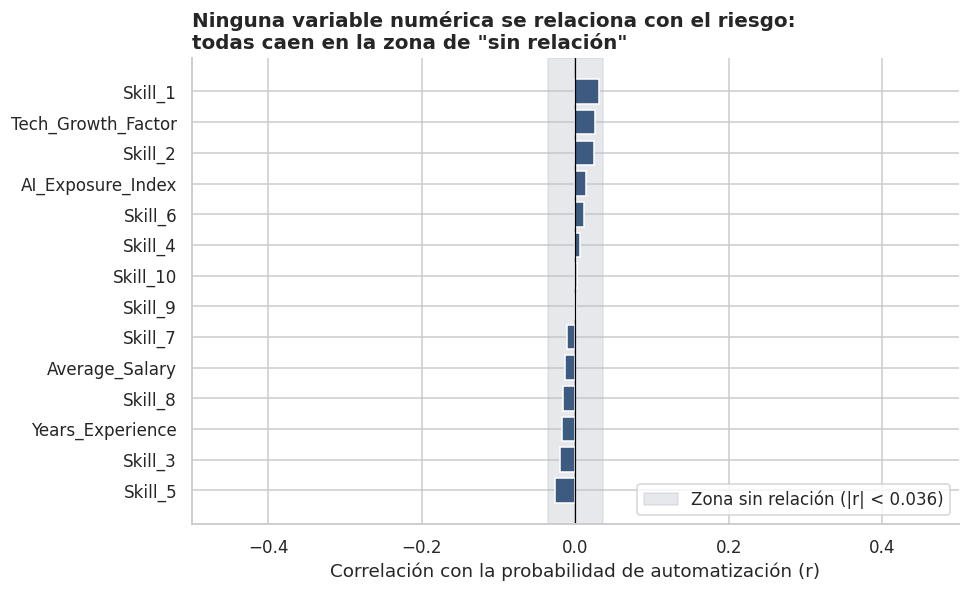

Correlación más fuerte (en valor absoluto): Skill_1 (r = +0.031)


In [18]:
numericas = [COL_SALARIO, COL_EXP, COL_EXPO, COL_TECH] + SKILLS
correlaciones = df_limpio[numericas].corrwith(df_limpio[COL_RIESGO]).sort_values()
umbral = 1.96 / np.sqrt(len(df_limpio))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.axvspan(-umbral, umbral, color=COLOR_GRIS, alpha=0.35, label=f'Zona sin relación (|r| < {umbral:.3f})')
ax.barh(correlaciones.index, correlaciones.values, color=COLOR_NEUTRO)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim(-0.5, 0.5)
ax.set_xlabel('Correlación con la probabilidad de automatización (r)')
ax.set_title('Ninguna variable numérica se relaciona con el riesgo:\ntodas caen en la zona de "sin relación"')
ax.legend(loc='lower right')
guardar(fig, '04_correlaciones')
plt.show()

print(f'Correlación más fuerte (en valor absoluto): {correlaciones.abs().idxmax()} '
      f'(r = {correlaciones[correlaciones.abs().idxmax()]:+.3f})')

**Interpretación:** las 14 variables numéricas tienen correlaciones entre **−0,03 y +0,03**, todas dentro de la zona de "sin relación". El eje va de −0,5 a 0,5 a propósito: con una escala más estrecha, diferencias de 0,01 parecerían importantes cuando no lo son.

- **Exposición a la IA: r = +0,014.** Es el resultado más contraintuitivo: en este dataset, estar más expuesto a la IA **no** implica más riesgo de automatización.
- **Habilidades (Skill_1 a Skill_10):** ninguna protege ni aumenta el riesgo. Como además son anónimas, no permiten recomendaciones del tipo "aprende la habilidad X".
- Recordatorio: **correlación no implica causalidad**. Aquí ni siquiera hay correlación.

## 2.5 Valores atípicos (outliers)
Usamos la regla del rango intercuartílico (IQR): un valor es atípico si está más de 1,5 × IQR por debajo de Q1 o por encima de Q3. Lo revisamos en el dataset completo y **dentro de cada profesión**, porque un riesgo de 0,30 es normal para Derecho, pero sería atípico para Construcción.

In [19]:
def mascara_outliers(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)


outliers = pd.DataFrame({
    'outliers (global)': {c: int(mascara_outliers(df_limpio[c]).sum()) for c in [COL_RIESGO, COL_SALARIO, COL_EXP, COL_EXPO, COL_TECH]},
    'outliers (dentro de cada profesión)': {
        c: int(df_limpio.groupby('profesion')[c].transform(mascara_outliers).sum())
        for c in [COL_RIESGO, COL_SALARIO, COL_EXP, COL_EXPO, COL_TECH]},
})
outliers

,outliers (global),outliers (dentro de cada profesión)
Automation_Probability_2030,0,0
Average_Salary,0,0
Years_Experience,0,0
AI_Exposure_Index,0,0
Tech_Growth_Factor,0,0


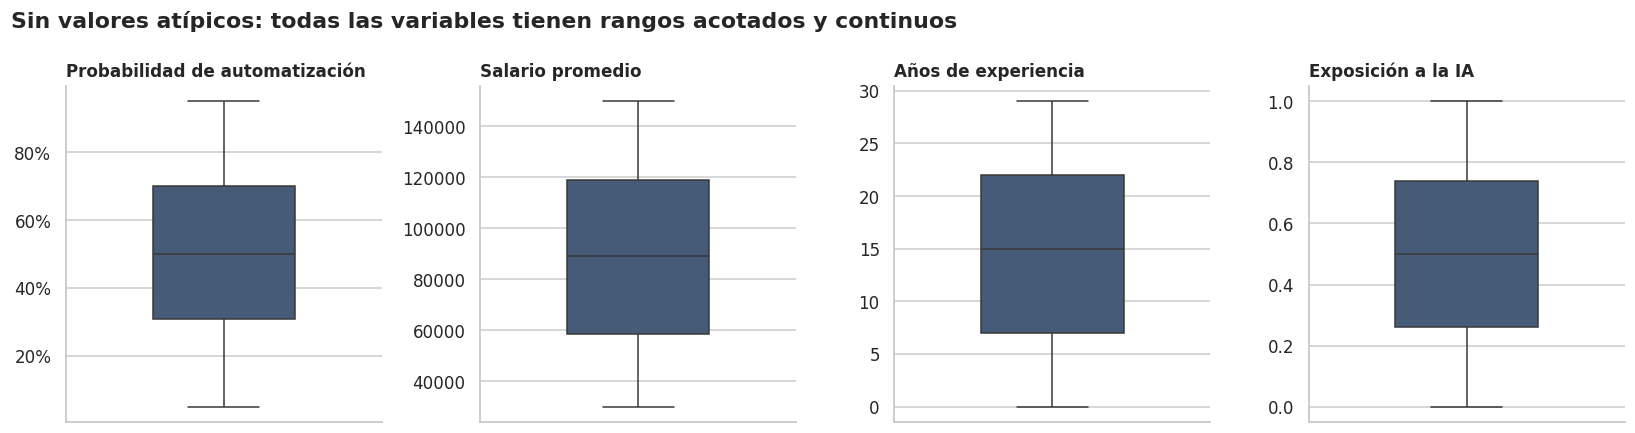

In [20]:
fig, ejes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (col, titulo) in zip(ejes, {COL_RIESGO: 'Probabilidad de automatización', COL_SALARIO: 'Salario promedio',
                                     COL_EXP: 'Años de experiencia', COL_EXPO: 'Exposición a la IA'}.items()):
    sns.boxplot(y=df_limpio[col], ax=ax, color=COLOR_NEUTRO, width=0.45)
    ax.set_title(titulo, fontsize=11)
    ax.set_ylabel('')
eje_porcentaje(ejes[0])
fig.suptitle('Sin valores atípicos: todas las variables tienen rangos acotados y continuos', fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

**Interpretación y decisión:** no hay **ningún** valor atípico, ni en el dataset completo ni dentro de cada profesión. Es lo esperado en datos sintéticos generados con rangos acotados y distribuciones parejas: no hay colas largas ni errores de digitación.

**Decisión:** se conservan todos los registros. No son errores de digitación, y eliminarlos sesgaría las medianas.

## 2.6 Hipótesis para la Etapa 3

| # | Hipótesis | Cómo la comprobamos |
|---|---|---|
| H1 | **La profesión es el factor dominante del riesgo** | Comparar modelos con y sin la profesión (3.3) |
| H2 | **La exposición a la IA, la educación, la experiencia, el salario y las habilidades no aportan** a la predicción una vez se conoce la profesión | Importancia por permutación en el modelo completo (3.3) |